# Выявление аномалий и пиковых нагрузок в пассажиропотоке станций Московского метрополитена

### Этап 1. Получение данных

Сначала изучим данные, предоставленные для проекта.

Набор данных содержит подробную информацию об общем количестве проходов пассажиров на станции метрополитена через турникеты по входу и об общем количестве выходов, осуществленных пассажирами со станций метрополитена.

Источник данных: Портал открытых данных Правительства Москвы: Пассажиропоток по станциям Московского метрополитена


In [406]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Скачиваем данные, определяем разделитель, пропускаем некоторые строки для корректной загрузки, конвертируем "0", "NULL", "None", "не указано" в NaN и загружаем данные в датафрейм.


In [407]:
df = pd.read_csv("C:\\Users\\Mariya\\PycharmProjects\\python-practice-analysis\\missing_values_project\\Пассажиропоток по станциям Московского метрополитена.csv", sep = '|', skiprows=[0, 1, 2, 3, 4, 6, 1380], na_values={'Входы пассажиров' : [0, 'не указано']})

Получение первых 10 строк таблицы.

In [408]:
df.head(10)

,Станция метрополитена,Линия,Год,Квартал,Входы пассажиров,Выходы пассажиров,global_id,NameOfStation_en,Line_en,Year_en,Quarter_en,IncomingPassengers_en,OutgoingPassengers_en,Unnamed: 13
0,Митино,Арбатско-Покровская линия,2021.0,I квартал,1913498.0,1829031.0,1.138976e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Волоколамская,Арбатско-Покровская линия,2021.0,I квартал,1236714.0,1222309.0,1.138976e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Строгино,Арбатско-Покровская линия,2021.0,I квартал,1938816.0,1903731.0,1.138976e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Крылатское,Арбатско-Покровская линия,2021.0,I квартал,1849616.0,1818208.0,1.138976e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Площадь Революции,Арбатско-Покровская линия,2021.0,I квартал,2324687.0,2319343.0,1.138976e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Бауманская,Арбатско-Покровская линия,2021.0,I квартал,3757697.0,3919091.0,1.138976e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Первомайская,Арбатско-Покровская линия,2021.0,I квартал,2554914.0,2542396.0,1.138976e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Беломорская,Замоскворецкая линия,2021.0,I квартал,2093304.0,2007519.0,1.138976e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Речной вокзал,Замоскворецкая линия,2021.0,I квартал,1976604.0,1932752.0,1.138976e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Водный стадион,Замоскворецкая линия,2021.0,I квартал,2798329.0,2787327.0,1.138976e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Общая информация о данных таблицы df

In [409]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1373 entries, 0 to 1372
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Станция метрополитена  1373 non-null   str    
 1   Линия                  1372 non-null   str    
 2   Год                    1372 non-null   float64
 3   Квартал                1372 non-null   str    
 4   Входы пассажиров       1339 non-null   float64
 5   Выходы пассажиров      1372 non-null   float64
 6   global_id              1372 non-null   float64
 7   NameOfStation_en       0 non-null      float64
 8   Line_en                0 non-null      float64
 9   Year_en                0 non-null      float64
 10  Quarter_en             0 non-null      float64
 11  IncomingPassengers_en  0 non-null      float64
 12  OutgoingPassengers_en  0 non-null      float64
 13  Unnamed: 13            0 non-null      float64
dtypes: float64(11), str(3)
memory usage: 150.3 KB


По результатам вызова df.info() были выявлены следующие особенности датасета:

Наличие пустых столбцов: Обнаружены неинформативные признаки (дублирующие английские названия и столбец Unnamed: 13). Целесообразно удалить их, оставив только ключевые: Станция, Линия, Год, Квартал, Входы, Выходы и global_id.

Типы данных: Столбцы Год и global_id определены как float64 (числа с плавающей точкой). Для текущих задач исследования это не является критичной ошибкой, однако в дальнейшем их можно привести к целочисленному типу (int).

### Этап 2. Очистка и обработка данных


Удаление дублирующих и неинформативных столбцов

In [410]:
columns_to_drop = [
    'NameOfStation_en',
    'Line_en',
    'Year_en',
    'Quarter_en',
    'IncomingPassengers_en',
    'OutgoingPassengers_en',
    'Unnamed: 13'
]

df = df.drop(columns=columns_to_drop)

Проверяем, сколько пропусков в каждом столбце


In [411]:
print("Пропуски до очистки:\n", df.isnull().sum())

Пропуски до очистки:
 Станция метрополитена     0
Линия                     1
Год                       1
Квартал                   1
Входы пассажиров         34
Выходы пассажиров         1
global_id                 1
dtype: int64


Обнаружено наличие пропусков. Оцениваем ситуацию.

In [412]:
df[df.isnull().any(axis=1)]

,Станция метрополитена,Линия,Год,Квартал,Входы пассажиров,Выходы пассажиров,global_id
22,Новослободская,Кольцевая линия,2021.0,I квартал,NaN,0.0,1.138976e+09
28,Рижская,Калужско-Рижская линия,2021.0,I квартал,NaN,0.0,1.138976e+09
133,Мневники,Большая кольцевая линия,2021.0,I квартал,NaN,0.0,1.138976e+09
150,Народное Ополчение,Большая кольцевая линия,2021.0,I квартал,NaN,0.0,1.138976e+09
309,Новослободская,Кольцевая линия,2021.0,II квартал,NaN,0.0,1.139050e+09
317,Рижская,Калужско-Рижская линия,2021.0,II квартал,NaN,0.0,1.139050e+09
456,Смоленская,Арбатско-Покровская линия,2021.0,I квартал,NaN,0.0,1.139051e+09
518,Смоленская,Арбатско-Покровская линия,2021.0,II квартал,NaN,0.0,1.139051e+09
546,Новослободская,Кольцевая линия,2021.0,III квартал,NaN,0.0,1.263041e+09
550,Рижская,Калужско-Рижская линия,2021.0,III квартал,NaN,0.0,1.263041e+09


Выводы:

- Обнаружены пропуски в столбце "Входы пассажиров". Выдвинута гипотеза: отсутствие данных связано с временным закрытием станций на ремонт или техническим сбоем. Поскольку эти записи отражают реальные периоды простоя, их удаление приведет к потере важного контекста. Принято решение заполнить пропуски нулевыми значениями (0)

- Обнаружена пустая строка 896 (//Нет данных). Удалить.


In [413]:
df['Входы пассажиров'] = df['Входы пассажиров'].fillna(0)

In [414]:
df = df.drop(index=896)


##  Этап 3. Выявление ключевых показателей

In [415]:
# Выводим базовую статистику по числовым столбцам
print(df[['Входы пассажиров', 'Выходы пассажиров']].describe())

       Входы пассажиров  Выходы пассажиров
count      1.372000e+03       1.372000e+03
mean       1.832504e+06       1.830236e+06
std        1.312783e+06       1.271424e+06
min        0.000000e+00       0.000000e+00
25%        8.019535e+05       8.156290e+05
50%        1.551653e+06       1.571906e+06
75%        2.626304e+06       2.665616e+06
max        7.660212e+06       6.456479e+06


In [416]:
# Найдем станцию с абсолютным максимумом пассажиропотока
df['Общий_пассажиропоток'] = df['Входы пассажиров'] + df['Выходы пассажиров']
max_station = df.loc[df['Общий_пассажиропоток'].idxmax()]
print(f"Самая загруженная станция: {max_station['Станция метрополитена']} ({max_station['Общий_пассажиропоток']} пассажиров)")

Самая загруженная станция: Комсомольская (14116691.0 пассажиров)


In [417]:
# Определяем сколько всего было входов по всем станциям за всё время
result = df['Входы пассажиров'].sum()
print(f'{result:.0f}')

2514195123


Выводы по этапу базовой статистики:

* Объем данных: В анализе участвует 1372 записи (станции × кварталы). Пропуски устранены, нулевые значения соответствуют периодам закрытия станций на ремонт.
* Распределение: Среднее значение 1.8 млн превышает медиану 1.5 млн. Это выдает присутствие выбросов - больших станций с огромным пассажиропотоком.
* Пиковые нагрузки: Абсолютным лидером по пассажиропотоку является станция Комсомольская (более 14.1 млн пассажиров за рассматриваемый период).
* Масштаб: Суммарное количество входов по всем станциям за весь период составило колоссальные 2.5 миллиарда пассажиров, что подчеркивает критическую важность метрополитена для города.

Этап 4. Графики

## Топ самых загруженных станций


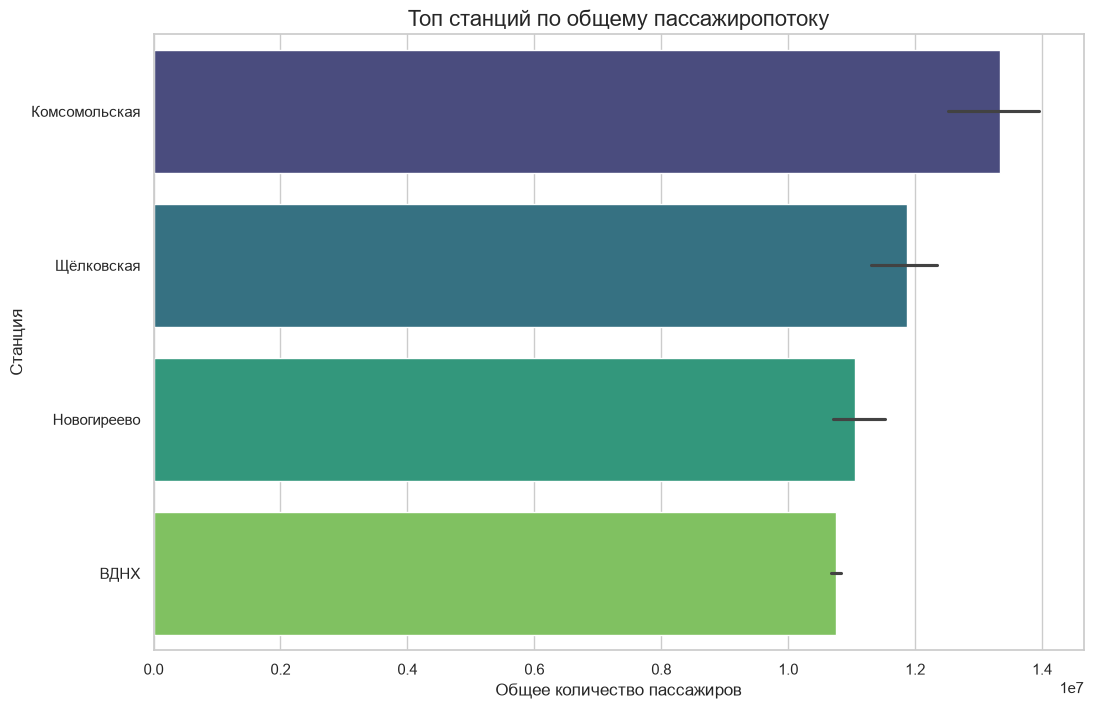

In [418]:
# Настройка стиля
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))

# Сортируем данные и берем топ-15
top_15 = df.sort_values(by='Общий_пассажиропоток', ascending=False).head(15)

# Строим горизонтальный график
sns.barplot(
    data=top_15,
    x='Общий_пассажиропоток',
    y='Станция метрополитена',
    hue='Станция метрополитена',
    palette='viridis',
    legend=False
)

plt.title('Топ станций по общему пассажиропотоку', fontsize=16)
plt.xlabel('Общее количество пассажиров', fontsize=12)
plt.ylabel('Станция', fontsize=12)
plt.show()

## Есть ли станции, которые работают только "на вход" или только "на выход"?

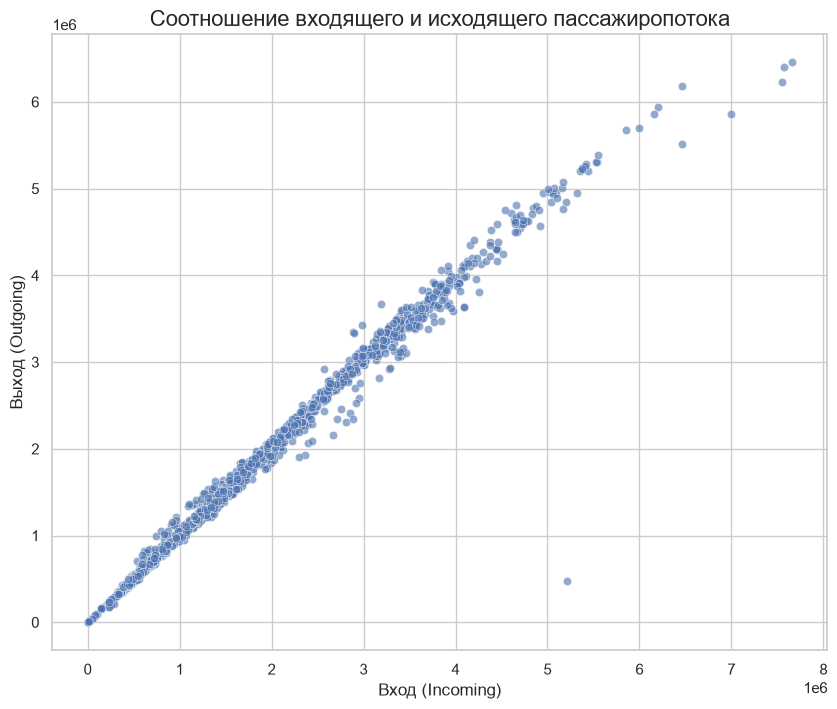

In [419]:
plt.figure(figsize=(10, 8))

# Точечный график
sns.scatterplot(data=df, x='Входы пассажиров', y='Выходы пассажиров', alpha=0.6)

plt.title('Соотношение входящего и исходящего пассажиропотока', fontsize=16)
plt.xlabel('Вход (Incoming)', fontsize=12)
plt.ylabel('Выход (Outgoing)', fontsize=12)

plt.show()

Диаграмма  рассеяния показала, что для подавляющего большинства станций пассажиропотоки на вход и выход сбалансированы (точки формируют линейный тренд). Выявлены аномальные наблюдения, где входящий поток значительно выше исходящего, что может быть связано с пиковыми нагрузками (утренние/вечерние часы)